# Facebook Ad Conversion Analysis + Predictive Model (Google Colab)

Dataset: `KAG_conversion_data.csv` (1,143 ad-level rows, 3 campaigns, ages 30-49, gender M/F, 40 interest codes)

**Kaise chalayein:**
1. Is notebook ko Google Colab mein kholein (File → Upload notebook).
2. CSV file ko Colab ke left panel (📁) mein upload karein, ya jab notebook poochhe tab select karein.
3. `Runtime → Run all` dabayein.

**GitHub par:** CSV file ko isi notebook ke saath same folder mein rakhein, taaki `Run all` seedha chale.

Sections: 1) Setup → 2) Data cleaning → 3) KPIs → 4) Segment analysis → 5) Statistical tests → 6) Interest smoothing → 7) Pareto & waste → 8) Anomaly detection → 9) Clustering → 10) ML model → 11) Budget reallocation → 12) Export → 13) Findings

## 1. Setup

In [1]:
import io, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, silhouette_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

### CSV load karein (local ya Colab upload)

In [2]:
CANDIDATES = ["KAG_conversion_data.csv", "d7767e1b-KAG_conversion_data.csv"]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)

if DATA_PATH is None:
    try:
        from google.colab import files          # Colab mein upload dialog khulega
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("CSV nahi mili. File ko notebook ke same folder mein rakhein.")

print("Using file:", DATA_PATH)

Using file: KAG_conversion_data.csv


## 2. Data loading aur cleaning

In [3]:
with open(DATA_PATH, "rb") as f:
    text = f.read().decode("utf-8", errors="replace")
# Line endings normalise karein (file mein CR-only line endings ho sakti hain)
text = text.replace("\r\n", "\n").replace("\r", "\n")
raw = pd.read_csv(io.StringIO(text))

df = raw.rename(columns={
    "ad_id": "ad_id", "xyz_campaign_id": "campaign", "fb_campaign_id": "fb_campaign",
    "age": "age", "gender": "gender", "interest": "interest",
    "Impressions": "impressions", "Clicks": "clicks", "Spent": "spent",
    "Total_Conversion": "total_conv", "Approved_Conversion": "approved_conv",
}).copy()

df["campaign"] = df["campaign"].astype(str)
df["interest"] = df["interest"].astype(str)
df["ad_id"] = df["ad_id"].astype(str)

# Derived metrics
df["ctr_pct"]              = df.clicks / df.impressions * 100
df["cpc"]                  = df.spent / df.clicks.replace(0, np.nan)
df["cpm"]                  = df.spent / df.impressions.replace(0, np.nan) * 1000
df["cpa"]                  = df.spent / df.approved_conv.replace(0, np.nan)
df["click_to_approved_pct"] = df.approved_conv / df.clicks.replace(0, np.nan) * 100
df["approval_rate"]        = df.approved_conv / df.total_conv.replace(0, np.nan)
df["converted"]            = (df.approved_conv > 0).astype(int)
df["conv_no_click"]        = ((df.total_conv > 0) & (df.clicks == 0)).astype(int)
df["zero_approved_high_spend"] = ((df.spent > 100) & (df.approved_conv == 0)).astype(int)
df["segment"] = df.campaign + " | " + df.age + " | " + df.gender

print("Shape:", df.shape)
df.head()

Shape: (1143, 21)


,ad_id,campaign,fb_campaign,age,gender,interest,impressions,clicks,spent,total_conv,approved_conv,ctr_pct,cpc,cpm,cpa,click_to_approved_pct,approval_rate,converted,conv_no_click,zero_approved_high_spend,segment
0,708746,916,103916,30-34,M,15,7350,1,1.43,2,1,0.01,1.43,0.19,1.43,100.00,0.50,1,0,0,916 | 30-34 | M
1,708749,916,103917,30-34,M,16,17861,2,1.82,2,0,0.01,0.91,0.10,NaN,0.00,0.00,0,0,0,916 | 30-34 | M
2,708771,916,103920,30-34,M,20,693,0,0.00,1,0,0.00,NaN,0.00,NaN,NaN,0.00,0,1,0,916 | 30-34 | M
3,708815,916,103928,30-34,M,28,4259,1,1.25,1,0,0.02,1.25,0.29,NaN,0.00,0.00,0,0,0,916 | 30-34 | M
4,708818,916,103928,30-34,M,28,4133,1,1.29,1,1,0.02,1.29,0.31,1.29,100.00,1.00,1,0,0,916 | 30-34 | M


### Data quality checks

In [4]:
checks = {
    "Missing values (total)": int(df.isna().sum().sum()),
    "Duplicate ad_id": int(df.ad_id.duplicated().sum()),
    "Approved > Total conversions": int((df.approved_conv > df.total_conv).sum()),
    "Clicks > Impressions": int((df.clicks > df.impressions).sum()),
    "Conversion bina click ke (tracking check)": int(df.conv_no_click.sum()),
    "Spend > 0 lekin clicks = 0": int(((df.spent > 0) & (df.clicks == 0)).sum()),
}
pd.Series(checks, name="count").to_frame()

,count
Missing values (total),981
Duplicate ad_id,0
Approved > Total conversions,0
Clicks > Impressions,0
Conversion bina click ke (tracking check),204
Spend > 0 lekin clicks = 0,0


**Interpretation:** Data clean hai. Koi missing value ya duplicate `ad_id` nahi hai, aur approved conversions kabhi total conversions se zyada nahi hain.

Sabse important flag hai **204 rows jinmein conversion hai lekin click zero hai**. Ye attribution (jaise view-through conversions) ka asar ho sakta hai, ya tracking ki galti. Final decisions se pehle ise Meta Events Manager mein check karna chahiye.

## 3. KPI overview

In [5]:
t = df[["impressions", "clicks", "spent", "total_conv", "approved_conv"]].sum()
kpis = pd.Series({
    "Ads": len(df),
    "Impressions": t.impressions,
    "Clicks": t.clicks,
    "CTR %": t.clicks / t.impressions * 100,
    "CPC": t.spent / t.clicks,
    "Total spend": t.spent,
    "Total conversions": t.total_conv,
    "Approved conversions": t.approved_conv,
    "CPA (approved)": t.spent / t.approved_conv,
    "Click → approved %": t.approved_conv / t.clicks * 100,
}, name="value").to_frame()
kpis

,value
Ads,"1,143.00"
Impressions,"213,434,828.00"
Clicks,"38,165.00"
CTR %,0.02
CPC,1.54
Total spend,"58,705.23"
Total conversions,"3,264.00"
Approved conversions,"1,079.00"
CPA (approved),54.41
Click → approved %,2.83


**Interpretation:** Har 1,000 impressions par lagbhag 0.18 clicks aaye (CTR ~0.018%). Har approved conversion ki lagat (CPA) lagbhag **54** hai. Clicks ka sirf ~2.8% approved conversion mein badla.

Ye baseline hai. Neeche ke sare segments isi se compare karke padhe jaayenge.

## 4. Segment analysis (campaign, age, gender, interest)

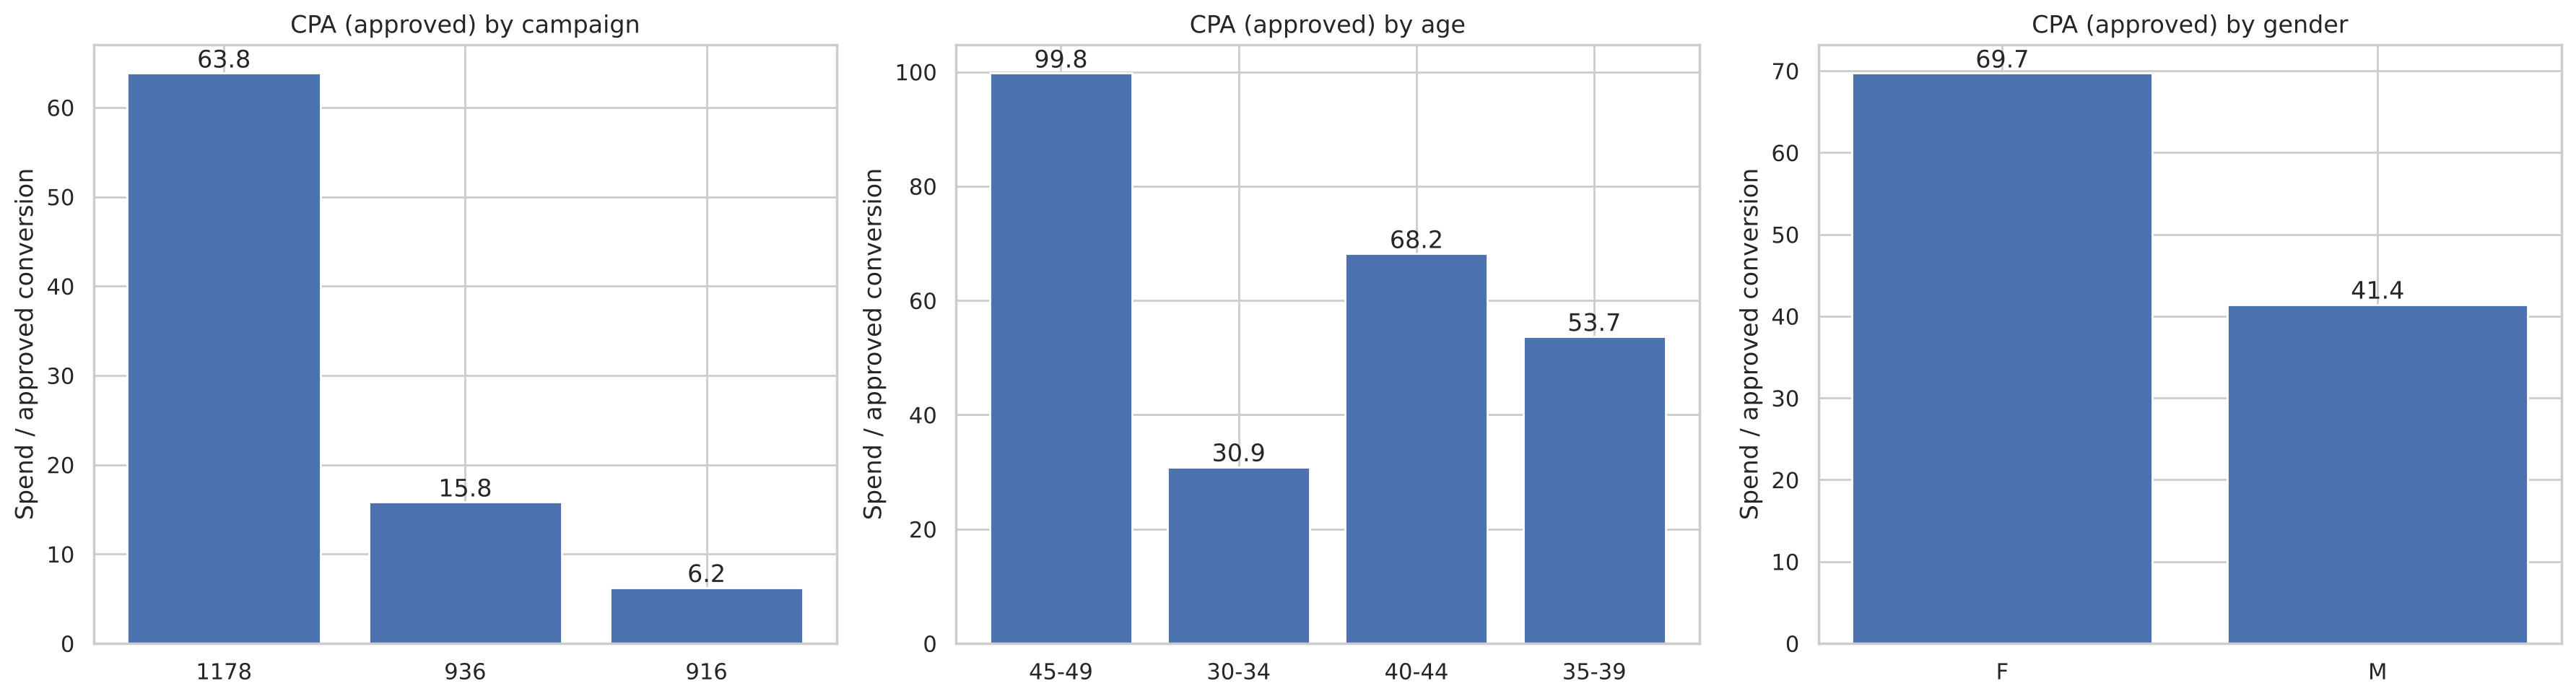


--- campaign ---


,ads,impressions,clicks,spent,total_conv,approved,CTR_%,CPC,CPA,click_to_approved_%,spend_share_%
campaign,,,,,,,,,,,
1178,625,204823716,36068,"55,662.15",2669,872,0.02,1.54,63.83,2.42,94.82
936,464,8128187,1984,"2,893.37",537,183,0.02,1.46,15.81,9.22,4.93
916,54,482925,113,149.71,58,24,0.02,1.32,6.24,21.24,0.26



--- age ---


,ads,impressions,clicks,spent,total_conv,approved,CTR_%,CPC,CPA,click_to_approved_%,spend_share_%
age,,,,,,,,,,,
45-49,259,63732858,13852,"20,750.67",684,208,0.02,1.50,99.76,1.50,35.35
30-34,426,67993019,9483,"15,252.40",1431,494,0.01,1.61,30.88,5.21,25.98
40-44,210,39604307,7736,"11,589.73",523,170,0.02,1.50,68.17,2.20,19.74
35-39,248,42104644,7094,"11,112.43",626,207,0.02,1.57,53.68,2.92,18.93



--- gender ---


,ads,impressions,clicks,spent,total_conv,approved,CTR_%,CPC,CPA,click_to_approved_%,spend_share_%
gender,,,,,,,,,,,
F,551,114862847,23878,"34,502.62",1644,495,0.02,1.44,69.70,2.07,58.77
M,592,98571981,14287,"24,202.61",1620,584,0.01,1.69,41.44,4.09,41.23


In [6]:
def summarize(by):
    g = df.groupby(by).agg(
        ads=("ad_id", "count"), impressions=("impressions", "sum"), clicks=("clicks", "sum"),
        spent=("spent", "sum"), total_conv=("total_conv", "sum"), approved=("approved_conv", "sum"),
    )
    g["CTR_%"] = g.clicks / g.impressions * 100
    g["CPC"] = g.spent / g.clicks
    g["CPA"] = g.spent / g.approved.replace(0, np.nan)
    g["click_to_approved_%"] = g.approved / g.clicks * 100
    g["spend_share_%"] = g.spent / g.spent.sum() * 100
    return g.sort_values("spent", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ["campaign", "age", "gender"]):
    s = summarize(col)
    bars = ax.bar(s.index.astype(str), s["CPA"], color="#4C72B0")
    ax.set_title(f"CPA (approved) by {col}")
    ax.set_ylabel("Spend / approved conversion")
    for b, v in zip(bars, s["CPA"]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

for col in ["campaign", "age", "gender"]:
    print(f"\n--- {col} ---")
    display(summarize(col).round(2))

**Interpretation:**
- **Campaign:** Campaign 1178 par lagbhag 95% spend hai, lekin uska CPA ~63.8 hai (sabse mehenga). 936 (CPA ~15.8) aur 916 (CPA ~6.2) efficient hain, par inka sample chhota hai. Scale karne se pehle sample badhana zaroori hai.
- **Age:** Umar badhne ke saath CPA badhta jaata hai: 30-34 par ~30.9, 35-39 par ~53.7, 40-44 par ~68.2, 45-49 par ~99.8. Click→approved rate bhi 5.2% se girkar 1.5% ho jaata hai. Sabse zyada spend 45-49 par hai, jo sabse kam efficient hai.
- **Gender:** Female par CPC sasta hai (1.44 vs 1.69), lekin approved conversion ki lagat female par ~70 aur male par ~41 hai. Sasta click hona conversion ki guarantee nahi hai.

### Heatmaps: Age × Gender aur Campaign × Gender (CPA)

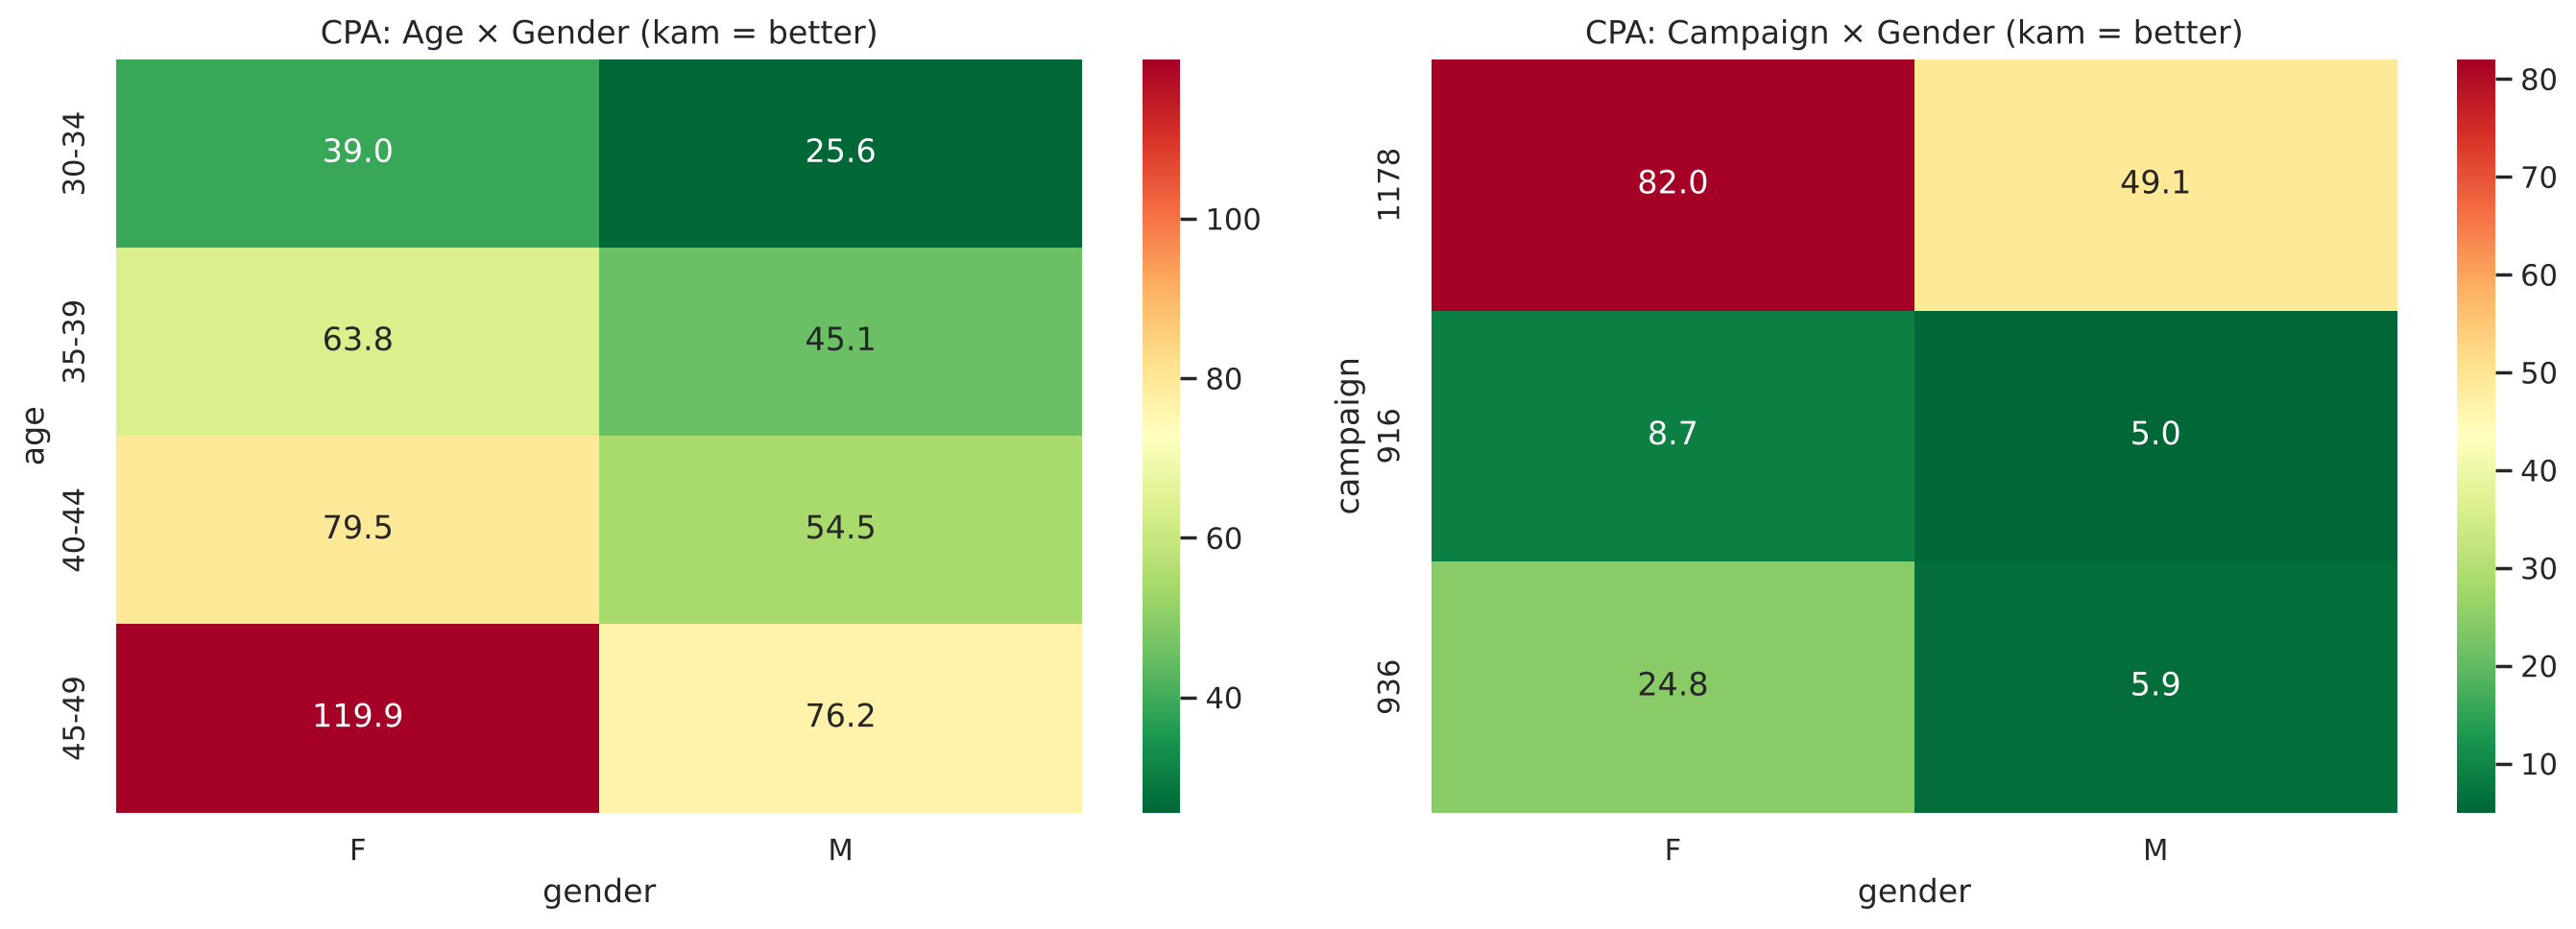

In [7]:
ag = df.groupby(["age", "gender"]).agg(spent=("spent", "sum"), approved=("approved_conv", "sum"))
ag_cpa = (ag.spent / ag.approved).unstack("gender")

cg = df.groupby(["campaign", "gender"]).agg(spent=("spent", "sum"), approved=("approved_conv", "sum"))
cg_cpa = (cg.spent / cg.approved).unstack("gender")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(ag_cpa, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axes[0])
axes[0].set_title("CPA: Age × Gender (kam = better)")
sns.heatmap(cg_cpa, annot=True, fmt=".1f", cmap="RdYlGn_r", ax=axes[1])
axes[1].set_title("CPA: Campaign × Gender (kam = better)")
plt.tight_layout(); plt.show()

**Interpretation:** Campaign × Gender heatmap se pata chalta hai ki farq campaign ke andar gender ka hai:
- **1178:** female CPA ~82, male CPA ~49
- **936:** female CPA ~24.8, male CPA ~5.9 (sabse bada gap)
- **916:** dono sasta hain (female ~8.7, male ~5.0)

Age × Gender heatmap mein green (kam CPA) cells wale combinations scale karne ke liye pehle candidates hain. Exact values heatmap ke numbers mein dekhein.

## 5. Statistical tests (kya farq real hai ya random?)

In [8]:
# 1) Chi-square: kya ad ka converted hona campaign/age/gender par depend karta hai?
print("Chi-square test (converted vs category)")
for col in ["gender", "age", "campaign"]:
    ct = pd.crosstab(df[col], df.converted)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"  {col:9s} chi2={chi2:8.2f}  dof={dof}  p={p:.4g}  {'SIGNIFICANT' if p < 0.05 else 'not significant'}")

# 2) Mann-Whitney: click→approved rate, male vs female
m = df[df.clicks > 0]
u, p = stats.mannwhitneyu(m[m.gender == "M"].click_to_approved_pct,
                          m[m.gender == "F"].click_to_approved_pct)
print(f"\nMann-Whitney (click→approved, M vs F): p={p:.4g}")

# 3) Kruskal-Wallis: click→approved rate, age groups
groups = [g.click_to_approved_pct.values for _, g in m.groupby("age")]
h, p = stats.kruskal(*groups)
print(f"Kruskal-Wallis (click→approved, age groups): H={h:.2f}, p={p:.4g}")

# 4) Bootstrap 95% CI for CPA by gender
def cpa_ci(d, n_boot=2000, seed=42):
    rng = np.random.default_rng(seed)
    s, a = d.spent.values, d.approved_conv.values
    idx = rng.integers(0, len(d), (n_boot, len(d)))
    ratios = s[idx].sum(1) / np.maximum(a[idx].sum(1), 1)
    return np.percentile(ratios, [2.5, 97.5])

print("\nCPA 95% bootstrap CI by gender:")
for gname, d in df.groupby("gender"):
    lo, hi = cpa_ci(d)
    print(f"  {gname}: CPA={d.spent.sum()/d.approved_conv.sum():.2f}  CI=({lo:.2f}, {hi:.2f})")

Chi-square test (converted vs category)
  gender    chi2=    1.70  dof=1  p=0.1917  not significant
  age       chi2=    2.39  dof=3  p=0.4956  not significant
  campaign  chi2=   67.67  dof=2  p=2.023e-15  SIGNIFICANT

Mann-Whitney (click→approved, M vs F): p=0.002684
Kruskal-Wallis (click→approved, age groups): H=22.66, p=4.757e-05

CPA 95% bootstrap CI by gender:
  F: CPA=69.70  CI=(61.53, 79.17)
  M: CPA=41.44  CI=(37.01, 47.06)


**Interpretation:**
- **Campaign** ka converted-ad par farq **statistically significant** hai (p < 0.001). Yaani campaign ka chayan real farq laata hai.
- **Gender aur age** ka converted-ad par farq significant nahi hai (p = 0.19 aur 0.50). Yaani ek ad ke approved conversion dene ka chance gender ya age se lagbhag same hai.
- Lekin **click→approved rate** par gender (Mann-Whitney p ≈ 0.003) aur age (Kruskal-Wallis p < 0.001) dono ka farq significant hai. Matlab gender aur age ka asar "kitne clicks convert hue" par dikhta hai.
- Bootstrap CI ke hisaab se female CPA (~61.5 se ~79.2) aur male CPA (~37.0 se ~47.1) ki ranges overlap nahi karti. Ye gap stable hai.

## 6. Interest codes: small sample ke liye smoothing (Bayesian shrinkage)

Overall click→approved rate: 2.83%

Top 10 interests (smoothed):


,ads,clicks,spent,approved,raw_rate_%,smoothed_rate_%,CPA
interest,,,,,,,
31,25,195,299.10,16,8.21,4.34,18.69
2,25,311,503.45,19,6.11,4.09,26.50
21,36,512,824.21,27,5.27,4.06,30.53
36,21,128,205.74,10,7.81,3.84,20.57
29,77,3315,"5,045.19",132,3.98,3.83,38.22
101,7,524,757.69,25,4.77,3.82,30.31
65,19,372,542.01,19,5.11,3.80,28.53
15,51,1609,"2,597.26",63,3.92,3.66,41.23
7,24,410,648.93,19,4.63,3.64,34.15



Bottom 10 interests (smoothed):


,ads,clicks,spent,approved,raw_rate_%,smoothed_rate_%,CPA
interest,,,,,,,
26,41,1113,"1,591.77",23,2.07,2.30,69.21
106,5,332,482.15,5,1.51,2.30,96.43
103,5,333,479.13,5,1.50,2.30,95.83
28,51,2025,"3,205.85",42,2.07,2.22,76.33
63,46,1675,"2,484.06",34,2.03,2.21,73.06
22,33,717,"1,039.86",12,1.67,2.15,86.65
25,26,1066,"1,603.86",19,1.78,2.12,84.41
105,7,453,647.80,6,1.32,2.11,107.97
109,6,572,815.82,8,1.40,2.06,101.98


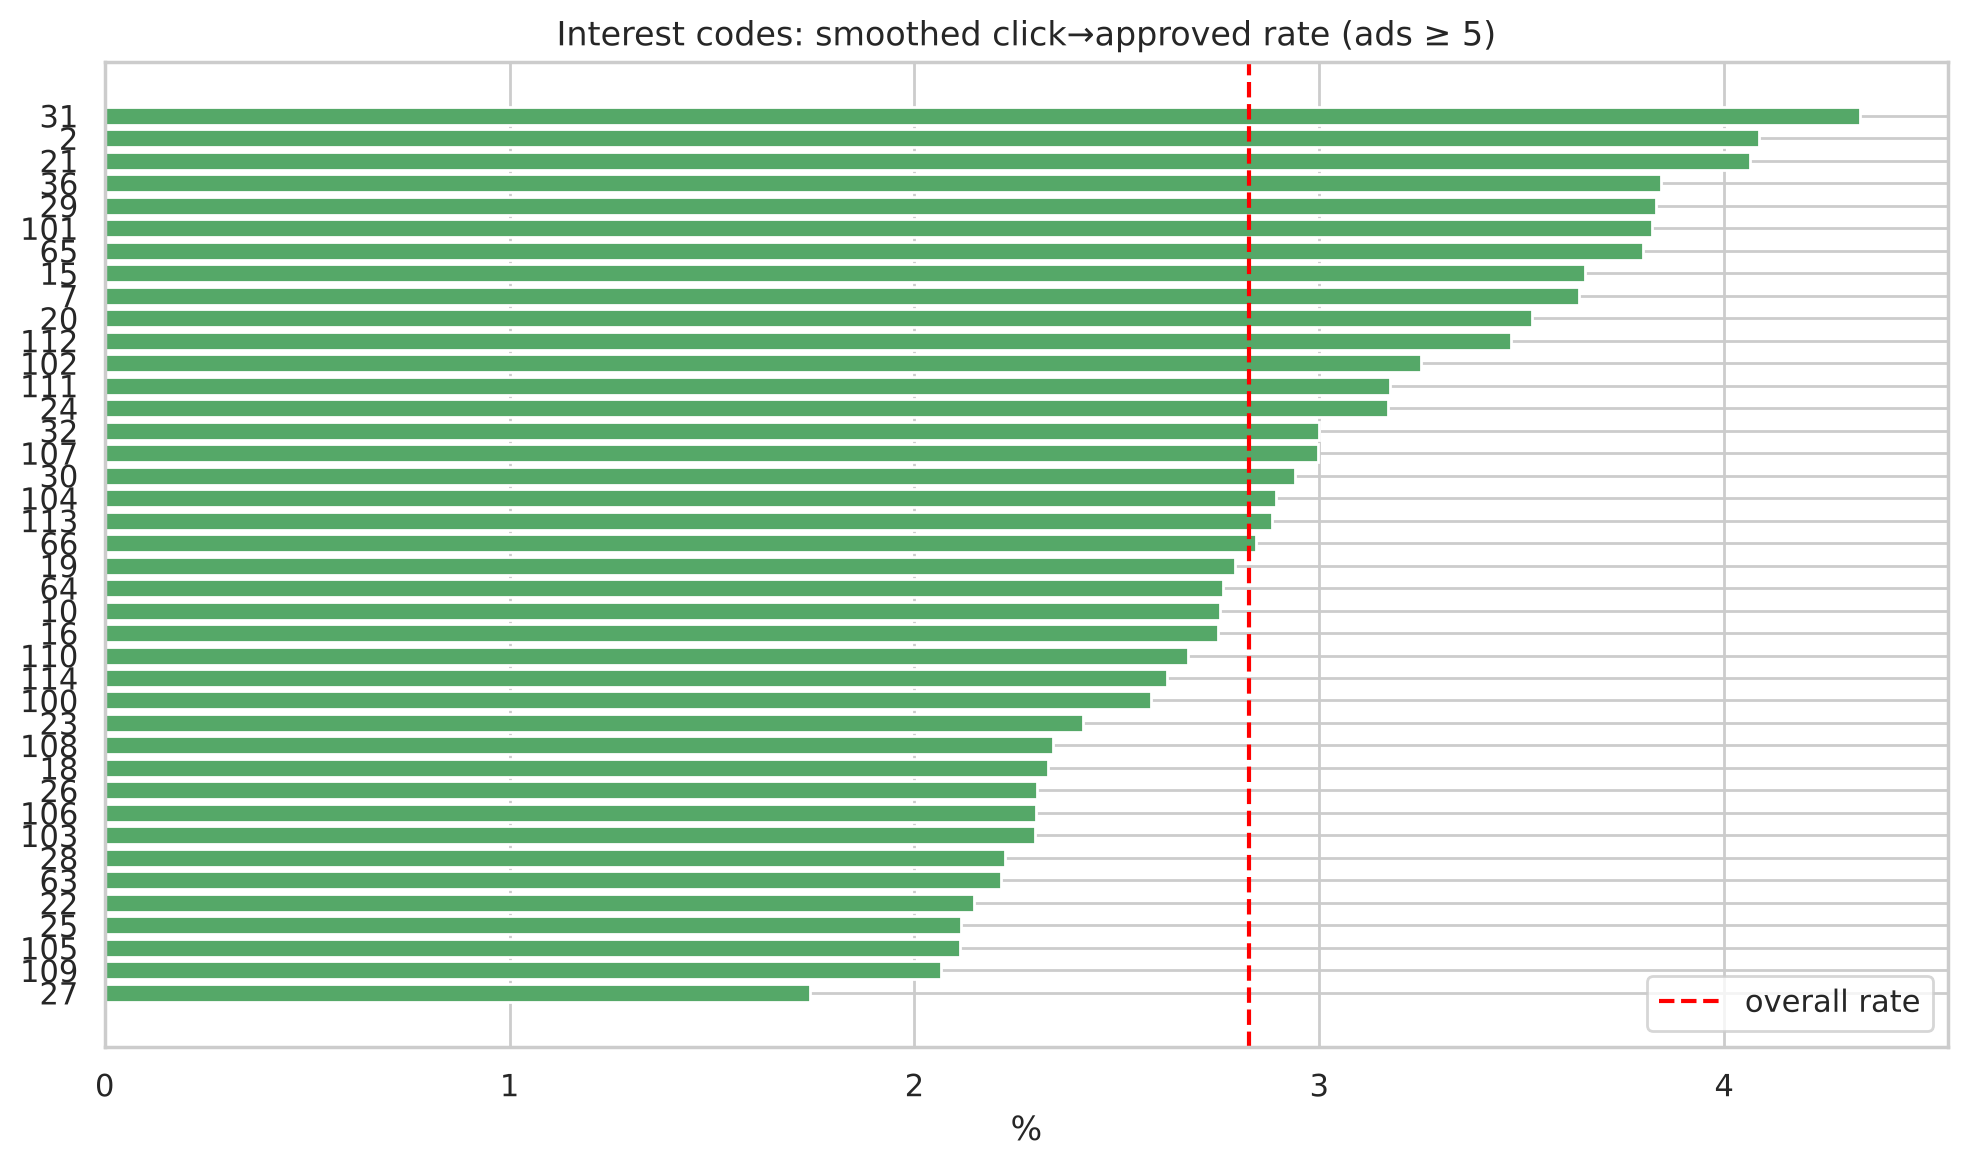

In [9]:
# Chhote samples par ek lucky ad ka rate misleading hota hai.
# Har interest ka rate overall rate ki taraf "khinchta" hai, jab tak clicks kam hain.
PRIOR_CLICKS = 500
overall_rate = df.approved_conv.sum() / df.clicks.sum()

ig = df.groupby("interest").agg(
    ads=("ad_id", "count"), clicks=("clicks", "sum"),
    spent=("spent", "sum"), approved=("approved_conv", "sum"),
)
ig["raw_rate_%"] = ig.approved / ig.clicks * 100
ig["smoothed_rate_%"] = (ig.approved + PRIOR_CLICKS * overall_rate) / (ig.clicks + PRIOR_CLICKS) * 100
ig["CPA"] = ig.spent / ig.approved.replace(0, np.nan)
ig_stable = ig[ig.ads >= 5].sort_values("smoothed_rate_%", ascending=False)

print(f"Overall click→approved rate: {overall_rate*100:.2f}%")
print("\nTop 10 interests (smoothed):")
display(ig_stable.head(10).round(2))
print("\nBottom 10 interests (smoothed):")
display(ig_stable.tail(10).round(2))

plt.figure(figsize=(10, 6))
s = ig_stable.sort_values("smoothed_rate_%")
plt.barh(s.index, s["smoothed_rate_%"], color="#55A868")
plt.axvline(overall_rate * 100, color="red", ls="--", label="overall rate")
plt.title("Interest codes: smoothed click→approved rate (ads ≥ 5)")
plt.xlabel("%"); plt.legend(); plt.tight_layout(); plt.show()

**Interpretation:** Smoothing ke baad top interests (31, 2, 21, 36, 29) ka rate lagbhag 3.8-4.3% hai, jabki overall rate 2.83% hai.
- **Interest 31** ka raw rate 8.2% dikhta hai, lekin sirf 195 clicks par. Smoothing ne use realistic range mein laaya.
- **Interest 29** ka sample sabse bada hai (77 ads, 3,315 clicks), isliye ise sabse bharosemand "stable winner" maanein.
- **Neeche wale** (27, 28, 63, 22, 25) overall se kam convert karte hain aur mehenge bhi hain (CPA ~73-96). **Interest 27** par sabse zyada spend (~5,176) hua hai, to yahan budget ka risk sabse bada hai.

## 7. Pareto analysis aur wasted spend

369 ads (32.3% of ads) se 80% approved conversions aaye hain
Zero-approved ads: 559 | spend: 14,754.42 (25.1% of total spend)
Spend > 100 lekin zero approved: 38 ads, spend 6,990.63


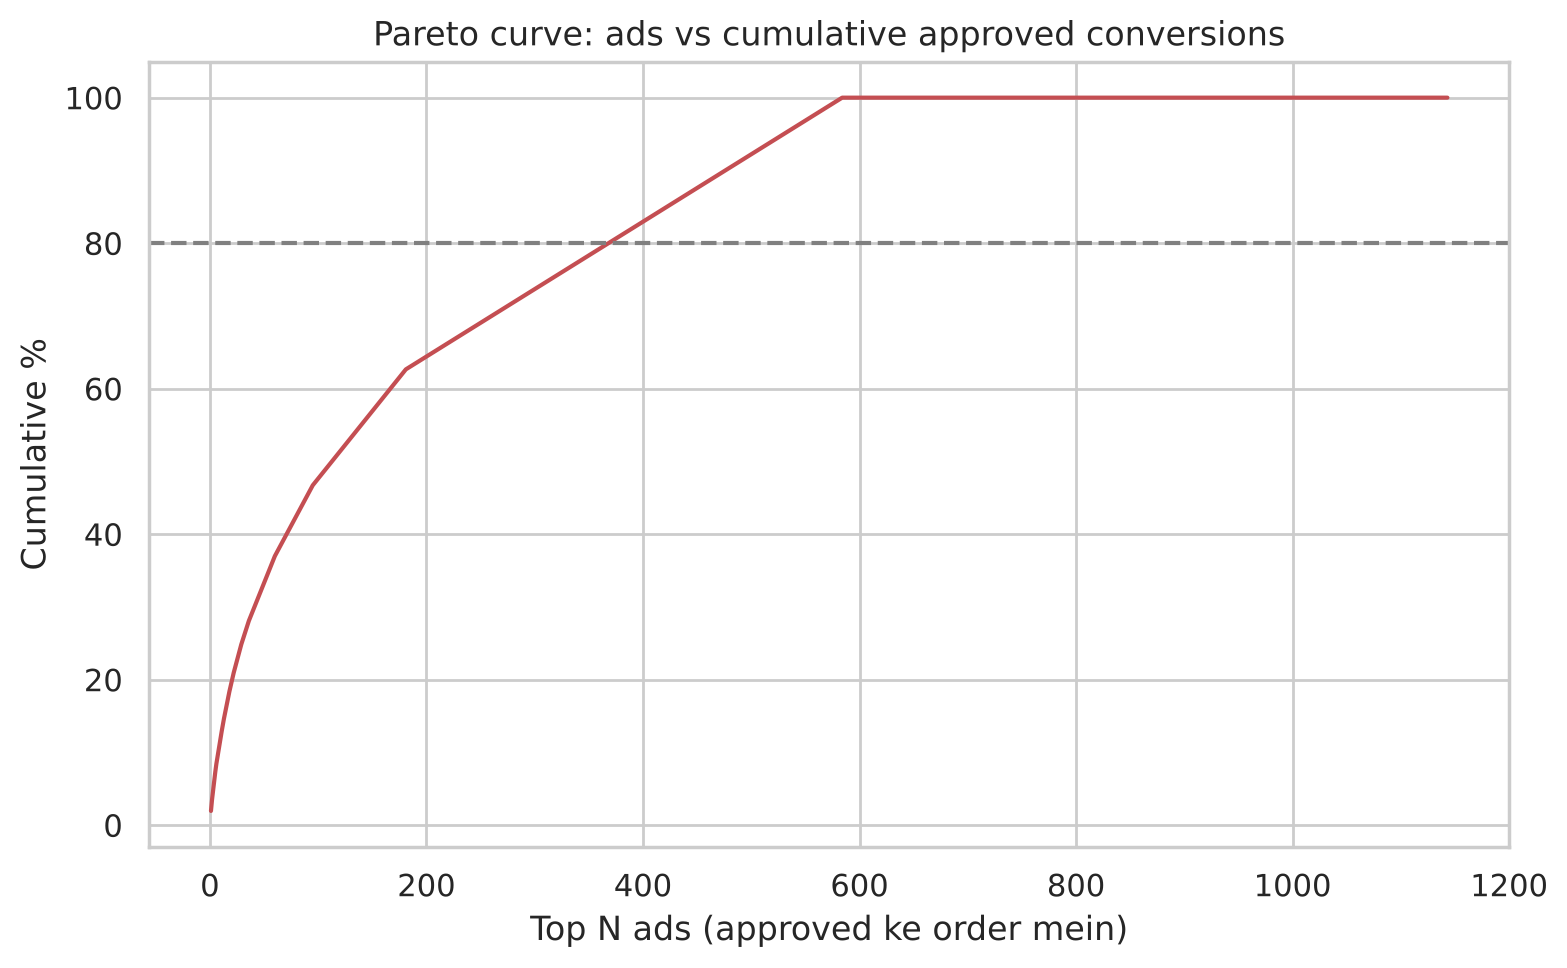

In [10]:
p = df.sort_values("approved_conv", ascending=False).copy()
p["cum_share"] = p.approved_conv.cumsum() / p.approved_conv.sum() * 100
n80 = int((p.cum_share < 80).sum() + 1)
print(f"{n80} ads ({n80/len(df)*100:.1f}% of ads) se 80% approved conversions aaye hain")

zero = df[df.approved_conv == 0]
print(f"Zero-approved ads: {len(zero)} | spend: {zero.spent.sum():,.2f} "
      f"({zero.spent.sum()/df.spent.sum()*100:.1f}% of total spend)")

high_waste = df[df.zero_approved_high_spend == 1].sort_values("spent", ascending=False)
print(f"Spend > 100 lekin zero approved: {len(high_waste)} ads, spend {high_waste.spent.sum():,.2f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(p) + 1), p.cum_share.values, color="#C44E52")
plt.axhline(80, ls="--", color="grey")
plt.title("Pareto curve: ads vs cumulative approved conversions")
plt.xlabel("Top N ads (approved ke order mein)"); plt.ylabel("Cumulative %")
plt.tight_layout(); plt.show()

**Interpretation:** Sirf **~32% ads (369)** ne 80% approved conversions diye, yaani conversions bahut concentrated hain.

**559 ads (~49%)** ne ek bhi approved conversion nahi diya, aur unpar ~14,754 spend hua (total ka ~25%). Budget ka bada hissa wo ads le rahe hain jo result nahi de rahe. Ye sabse direct cost-saving lever hai.

## 8. Anomaly detection (data quality + unusual ads)

In [11]:
X_iso = np.log1p(df[["impressions", "clicks", "spent", "total_conv", "approved_conv"]])
iso = IsolationForest(contamination=0.03, random_state=42).fit(X_iso)
df["anomaly"] = (iso.predict(X_iso) == -1).astype(int)

print("Isolation Forest anomalies:", int(df.anomaly.sum()))
display(df.loc[df.anomaly == 1, ["ad_id", "segment", "impressions", "clicks", "spent",
                                  "total_conv", "approved_conv"]].sort_values("spent", ascending=False).head(10))

print(f"\nConversion bina click ke: {df.conv_no_click.sum()} rows → tracking/attribution check karein")

Isolation Forest anomalies: 35


,ad_id,segment,impressions,clicks,spent,total_conv,approved_conv
525,1121100,1178 | 30-34 | M,3052003,340,639.95,60,17
860,1121814,1178 | 30-34 | F,2223278,421,612.30,38,13
765,1121601,1178 | 45-49 | M,2286228,353,603.38,16,7
1026,1122265,1178 | 45-49 | F,1428421,367,541.70,10,0
995,1122193,1178 | 45-49 | F,1358324,346,465.08,8,2
867,1121824,1178 | 30-34 | F,1705246,295,429.48,23,10
807,1121677,1178 | 45-49 | M,1391924,258,422.84,17,10
662,1121367,1178 | 35-39 | M,1447755,233,420.58,11,8
1041,1122304,1178 | 45-49 | F,1111156,282,402.30,5,0
969,1122112,1178 | 40-44 | F,1083259,276,390.26,11,0



Conversion bina click ke: 204 rows → tracking/attribution check karein


**Interpretation:** Isolation Forest ne 35 ads ko unusual flag kiya. Inmein sabse upar wo ads hain jinpar bada spend hua lekin conversion zero hai:
- ad `1122265` (~542 spend, 0 approved)
- ad `1122304` (~402 spend, 0 approved)
- ad `1122112` (~390 spend, 0 approved)

Ad `1121100` (~640 spend) ne 17 approved diye, to wo high-spend par bhi accha performer hai. Ye flags sirf review ke liye hain, automatic pause ke liye nahi.

## 9. Clustering: ads ko performance groups mein baantna

In [12]:
X_cl = pd.DataFrame({
    "log_impr": np.log1p(df.impressions),
    "log_spend": np.log1p(df.spent),
    "log_approved": np.log1p(df.approved_conv),
    "ctr": df.ctr_pct.fillna(0),
    "cvr": df.click_to_approved_pct.fillna(0),
})
Xs = StandardScaler().fit_transform(X_cl)

sil = {k: silhouette_score(Xs, KMeans(k, n_init=10, random_state=42).fit_predict(Xs)) for k in range(2, 7)}
print("Silhouette scores:", {k: round(v, 3) for k, v in sil.items()})
K = max(sil, key=sil.get)
df["cluster"] = KMeans(K, n_init=10, random_state=42).fit_predict(Xs)

prof = df.groupby("cluster").agg(
    ads=("ad_id", "count"), avg_spend=("spent", "mean"), avg_approved=("approved_conv", "mean"),
    median_cpa=("cpa", "median"), median_cvr=("click_to_approved_pct", "median"),
    median_ctr=("ctr_pct", "median"),
).sort_values("avg_approved", ascending=False)
print(f"\nChosen k = {K}")
display(prof.round(2))
print("Interpretation: upar wale clusters 'stars' hain; neeche wale 'wasters' ho sakte hain. Profile dekh kar naam dein.")

Silhouette scores: {2: 0.347, 3: 0.409, 4: 0.396, 5: 0.398, 6: 0.403}

Chosen k = 3


,ads,avg_spend,avg_approved,median_cpa,median_cvr,median_ctr
cluster,,,,,,
2,632,91.21,1.38,39.03,1.91,0.02
0,112,2.99,1.16,2.16,50.00,0.02
1,399,1.81,0.19,0.00,0.00,0.00


Interpretation: upar wale clusters 'stars' hain; neeche wale 'wasters' ho sakte hain. Profile dekh kar naam dein.


**Interpretation:** Silhouette score k=3 par sabse achha (0.41) aaya, isliye 3 clusters use hue:
- **Cluster 2 (632 ads, avg spend ~91, avg approved ~1.4, median CPA ~39):** "Core performers". Inpar real budget laga aur result bhi aaya.
- **Cluster 0 (112 ads, avg spend ~3):** CPA aur conversion rate dono accha dikhte hain, lekin spend bahut kam hai. Ye "small tests" hain jo promising lagte hain, par sample chhota hai. Inka median CPA kam dikhna isi wajah se hai.
- **Cluster 1 (399 ads, avg spend ~1.8, avg approved ~0.19):** Lagbhag koi conversion nahi aur spend bhi lagbhag nahi. Ye "untested / dead" ads hain.

Cluster ke naam aap apne hisaab se badal sakte hain.

## 10. Predictive model: kaunsa ad conversion dega?

Target: `converted` = 1 agar ad ne kam se kam 1 approved conversion diya.
Features: campaign, age, gender, interest (targeting setup).
**Note:** spend aur clicks ko jaan-boojh kar exclude kiya hai, kyunki ye outcome ke saath badhte hain (data leakage). Isse model "targeting" ke basis par seekhta hai.

LogisticRegression   5-fold ROC-AUC: 0.656 ± 0.014


RandomForest         5-fold ROC-AUC: 0.639 ± 0.011



RandomForest holdout ROC-AUC: 0.622


campaign    0.09
interest    0.03
gender     -0.01
age        -0.01
dtype: float64


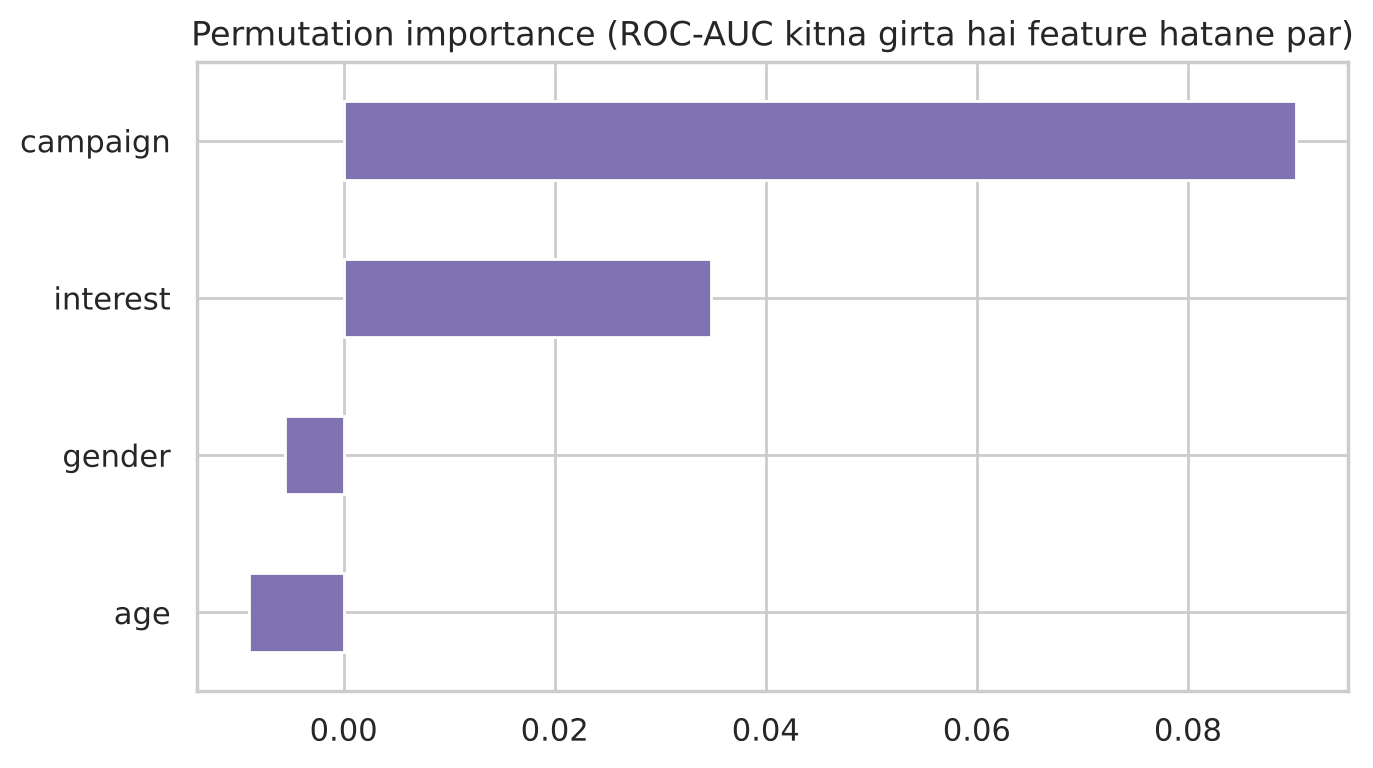

In [13]:
cat_cols = ["campaign", "age", "gender", "interest"]
X = df[cat_cols]
y = df.converted

pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])

models = {
    "LogisticRegression": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
    "RandomForest": Pipeline([("pre", pre), ("clf", RandomForestClassifier(
        n_estimators=400, min_samples_leaf=3, class_weight="balanced", random_state=42))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, model in models.items():
    auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    print(f"{name:20s} 5-fold ROC-AUC: {auc.mean():.3f} ± {auc.std():.3f}")

# Holdout test + permutation importance
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
rf = models["RandomForest"].fit(Xtr, ytr)
print(f"\nRandomForest holdout ROC-AUC: {roc_auc_score(yte, rf.predict_proba(Xte)[:, 1]):.3f}")

pi = permutation_importance(rf, Xte, yte, n_repeats=20, random_state=42, scoring="roc_auc")
imp = pd.Series(pi.importances_mean, index=cat_cols).sort_values()
print(imp.sort_values(ascending=False).round(4))
plt.figure(figsize=(7, 4))
imp.plot.barh(color="#8172B2")
plt.title("Permutation importance (ROC-AUC kitna girta hai feature hatane par)")
plt.tight_layout(); plt.show()

**Interpretation (feature importance):**
- **Campaign** sabse important feature hai (importance ~0.09). Campaign badalne par prediction sabse zyada badalti hai.
- **Interest** ka asar chhota hai (~0.03).
- **Age aur gender** ka importance lagbhag zero hai. Yaani ye model mein extra prediction nahi jodte, bhale hi click→approved rate par inka farq significant ho.

Model ka ROC-AUC ~0.62-0.66 hai, to ye sirf ek kamzor predictor hai. Ye batata hai ki conversion sirf targeting settings par depend nahi karta. Creative, landing page aur offer bhi matter karte hain, jo is dataset mein nahi hain.

**Kaise padhein:** ROC-AUC 0.5 ka matlab random guessing; 0.7+ ko kaam ka maana jata hai. Agar AUC kam aaye to iska matlab hai ki targeting features akele conversion ko zyada predict nahi karte, aur ye ek valid finding hai.

## 11. Budget reallocation (heuristic)

In [14]:
seg = df.groupby("segment").agg(spent=("spent", "sum"), approved=("approved_conv", "sum"), ads=("ad_id", "count"))
seg = seg[seg.spent > 0].copy()
seg["approved_per_1000"] = seg.approved / seg.spent * 1000   # efficiency
seg["CPA"] = seg.spent / seg.approved.replace(0, np.nan)

def allocate(seg, total_budget, cap_multiplier=1.5):
    """Efficiency ke order mein budget bharo. Har segment ki max = historical spend x cap_multiplier."""
    s = seg.sort_values("approved_per_1000", ascending=False)
    remaining = total_budget
    rows = {}
    for name, row in s.iterrows():
        x = min(row.spent * cap_multiplier, remaining)
        rows[name] = x
        remaining -= x
        if remaining <= 0:
            break
    out = pd.DataFrame.from_dict(rows, orient="index", columns=["new_budget"])
    out["approved_per_1000"] = seg.loc[out.index, "approved_per_1000"]
    out["expected_approved"] = out.new_budget * out.approved_per_1000 / 1000
    return out.sort_values("new_budget", ascending=False)

TOTAL = df.spent.sum()
baseline_approved = seg.approved.sum()
alloc = allocate(seg, TOTAL)

print(f"Current budget {TOTAL:,.0f} → approved {baseline_approved:,.0f}")
print(f"Reallocated budget {alloc.new_budget.sum():,.0f} → expected approved {alloc.expected_approved.sum():,.0f} (linear estimate)")
print("\nTop 15 segments ko zyada budget:")
display(alloc.head(15).round(2))
print("⚠️ Ye linear extrapolation hai. Asal mein spend badhne par efficiency girti hai (diminishing returns), isliye ise test karke hi lagu karein.")

Current budget 58,705 → approved 1,079
Reallocated budget 58,705 → expected approved 1,358 (linear estimate)

Top 15 segments ko zyada budget:


,new_budget,approved_per_1000,expected_approved
1178 | 30-34 | M,"11,214.10",32.50,364.50
1178 | 30-34 | F,"10,964.34",20.79,228.00
1178 | 45-49 | M,"9,749.95",11.61,113.19
1178 | 35-39 | F,"8,606.91",12.55,108.00
1178 | 35-39 | M,"7,451.13",19.12,142.50
1178 | 40-44 | M,"6,154.17",14.87,91.50
936 | 45-49 | F,"2,149.39",16.05,34.50
936 | 40-44 | F,563.57,31.94,18.00
936 | 35-39 | F,476.69,69.23,33.00
936 | 30-34 | F,380.90,153.59,58.50


⚠️ Ye linear extrapolation hai. Asal mein spend badhne par efficiency girti hai (diminishing returns), isliye ise test karke hi lagu karein.


**Interpretation:** Same total budget (~58,705) ko efficiency wale segments mein dene par expected approved conversions ~1,358 aate hain, jo current ~1,079 se lagbhag 26% zyada hai.

Sabse zyada budget **1178 | 30-34 | M** (~11,214) aur **1178 | 30-34 | F** (~10,964) ko mila hai.

**Caveat:** Ye estimate linear hai, yaani maan liya gaya hai ki spend badhne par efficiency same rahegi. Asal mein diminishing returns hote hain, to ye optimistic estimate hai. Isliye pehle 2-3 hafte ke liye 10-15% budget shift karke real result dekhein.

## 12. Export (reports)

In [15]:
os.makedirs("outputs", exist_ok=True)
summarize("segment").to_csv("outputs/segment_summary.csv")
(df[df.zero_approved_high_spend == 1][["ad_id", "segment", "spent", "clicks", "approved_conv"]]
   .sort_values("spent", ascending=False)
   .to_csv("outputs/waste_ads_to_review.csv", index=False))
df[df.conv_no_click == 1][["ad_id", "segment", "impressions", "total_conv", "approved_conv"]].to_csv(
    "outputs/tracking_check_rows.csv", index=False)
alloc.to_csv("outputs/budget_reallocation.csv")
df.to_csv("outputs/cleaned_with_features.csv", index=False)
print("Saved:", os.listdir("outputs"))

Saved: ['budget_reallocation.csv', 'cleaned_with_features.csv', 'waste_ads_to_review.csv', 'segment_summary.csv', 'tracking_check_rows.csv']


## 13. Dashboard
Sabhi key metrics ek hi image mein. Ye image `outputs/dashboard.png` mein bhi save hoti hai.

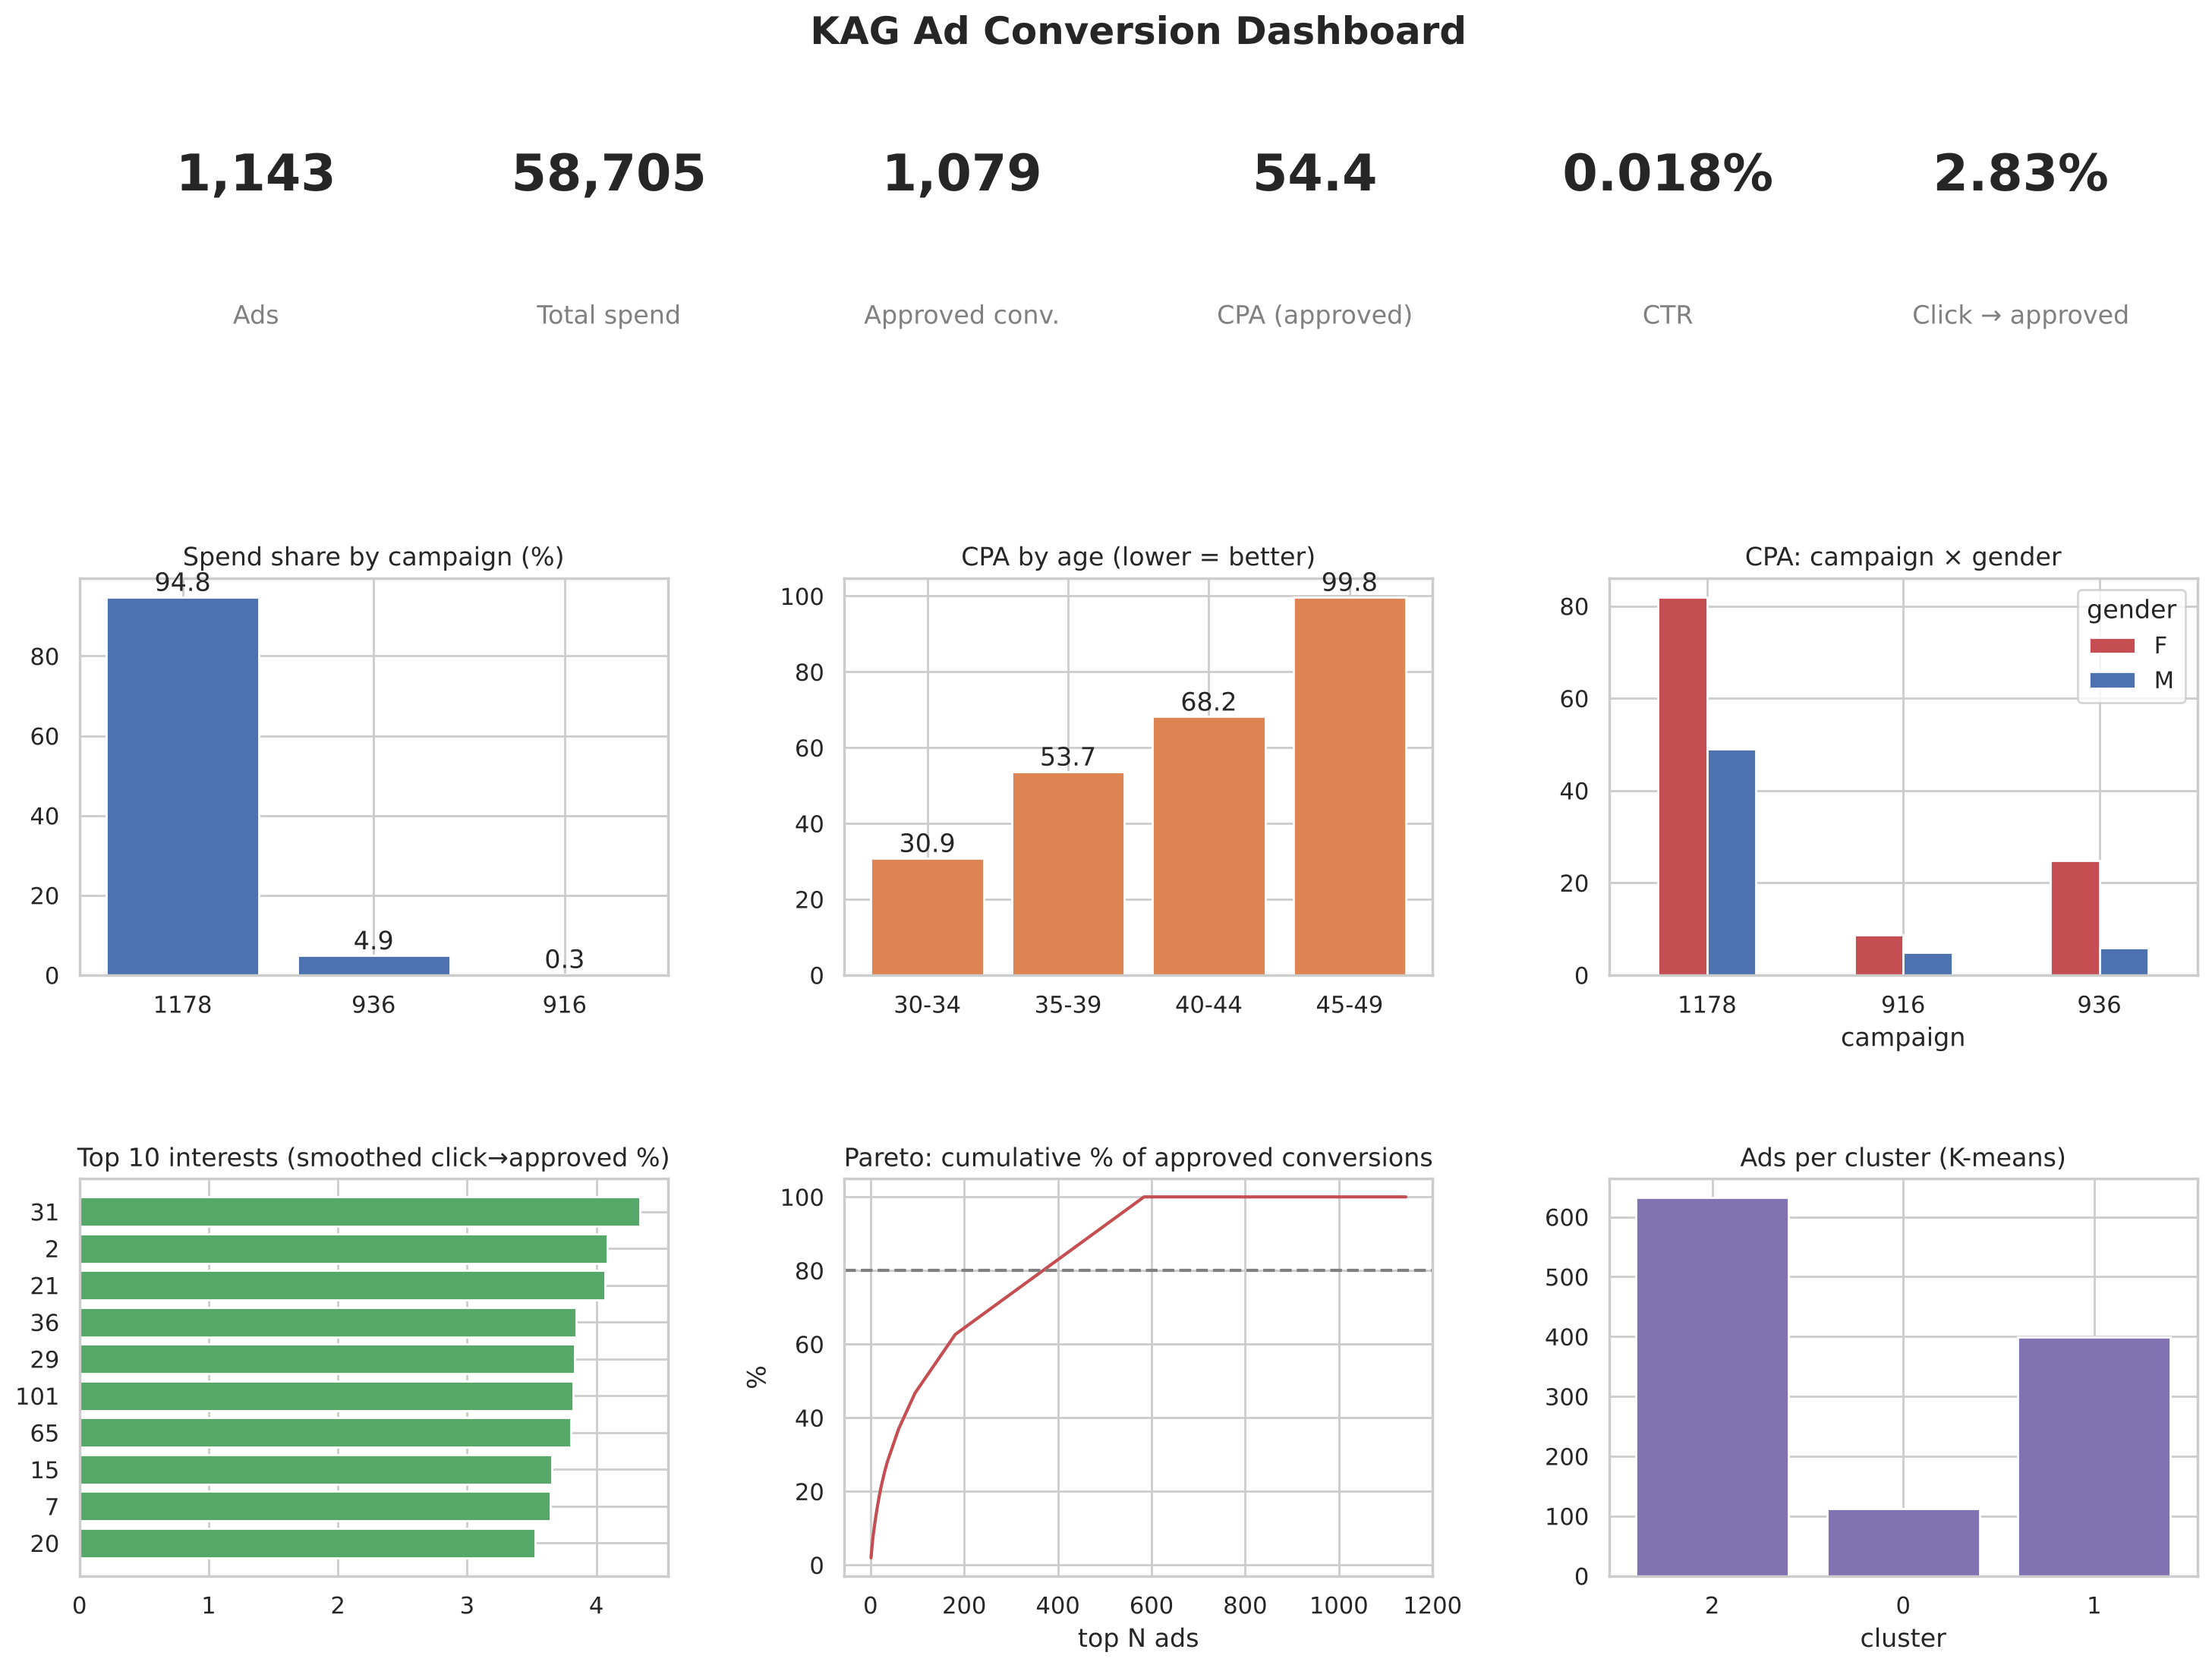

In [16]:
t = df[["impressions", "clicks", "spent", "total_conv", "approved_conv"]].sum()
fig = plt.figure(figsize=(18, 13))
gs = fig.add_gridspec(3, 3, hspace=0.55, wspace=0.3, height_ratios=[0.8, 1, 1])

# Row 0: KPI tiles
ax0 = fig.add_subplot(gs[0, :]); ax0.axis("off")
tiles = [
    ("Ads", f"{len(df):,}"),
    ("Total spend", f"{t.spent:,.0f}"),
    ("Approved conv.", f"{t.approved_conv:,.0f}"),
    ("CPA (approved)", f"{t.spent / t.approved_conv:,.1f}"),
    ("CTR", f"{t.clicks / t.impressions * 100:.3f}%"),
    ("Click → approved", f"{t.approved_conv / t.clicks * 100:.2f}%"),
]
for i, (lab, val) in enumerate(tiles):
    x = (i + 0.5) / len(tiles)
    ax0.text(x, 0.62, val, ha="center", va="center", fontsize=24, fontweight="bold", transform=ax0.transAxes)
    ax0.text(x, 0.18, lab, ha="center", va="center", fontsize=12, color="grey", transform=ax0.transAxes)
ax0.set_title("KAG Ad Conversion Dashboard", fontsize=18, fontweight="bold")

# Row 1
ax1 = fig.add_subplot(gs[1, 0])
s1 = summarize("campaign")
ax1.bar(s1.index, s1["spend_share_%"], color="#4C72B0")
ax1.set_title("Spend share by campaign (%)")
for i, v in enumerate(s1["spend_share_%"]):
    ax1.text(i, v, f"{v:.1f}", ha="center", va="bottom")

ax2 = fig.add_subplot(gs[1, 1])
s2 = summarize("age").sort_index()
ax2.bar(s2.index, s2["CPA"], color="#DD8452")
ax2.set_title("CPA by age (lower = better)")
for i, v in enumerate(s2["CPA"]):
    ax2.text(i, v, f"{v:.1f}", ha="center", va="bottom")

ax3 = fig.add_subplot(gs[1, 2])
cg_cpa.plot.bar(ax=ax3, rot=0, color=["#C44E52", "#4C72B0"])
ax3.set_title("CPA: campaign × gender")
ax3.set_xlabel("campaign"); ax3.legend(title="gender")

# Row 2
ax4 = fig.add_subplot(gs[2, 0])
top10 = ig_stable.head(10).sort_values("smoothed_rate_%")
ax4.barh(top10.index, top10["smoothed_rate_%"], color="#55A868")
ax4.set_title("Top 10 interests (smoothed click→approved %)")

ax5 = fig.add_subplot(gs[2, 1])
pareto_df = df.sort_values("approved_conv", ascending=False)
ax5.plot(range(1, len(pareto_df) + 1), pareto_df.approved_conv.cumsum() / pareto_df.approved_conv.sum() * 100, color="#C44E52")
ax5.axhline(80, ls="--", color="grey")
ax5.set_title("Pareto: cumulative % of approved conversions")
ax5.set_xlabel("top N ads"); ax5.set_ylabel("%")

ax6 = fig.add_subplot(gs[2, 2])
ax6.bar(prof.index.astype(str), prof["ads"], color="#8172B2")
ax6.set_title("Ads per cluster (K-means)")
ax6.set_xlabel("cluster")

plt.savefig("outputs/dashboard.png", dpi=110, bbox_inches="tight")
plt.show()

## 14. Findings (is dataset par pehle ke analysis se)

- **Campaign 1178** spend ka ~95% kharch karta hai, lekin uska CPA sabse zyada (~63.8) hai. **936** (CPA ~15.8) aur **916** (CPA ~6.2) efficient hain.
- **Umar badhne par** conversion rate girta hai (30-34: 5.2% click→approved, 45-49: 1.5%), aur 45-49 par spend sabse zyada hai.
- **Gender:** female par CPC sasta hai, lekin conversion kam; male par click→approved zyada (~4.1% vs ~2.1%). Campaign 936 mein female CPA ~24.8, male ~5.9.
- **Interests:** 29, 15, 20 jaise interests stable aur efficient hain; 27, 28, 63 mehenge hain.
- **Waste:** ~559 ads ne zero approved diye, jinka spend total ka ~25% hai.
- **Data issue:** 204 rows mein conversion hai lekin click zero hai; tracking check karein.
- **Model:** sirf campaign/age/gender/interest se conversion predict karna kamzor hai (ROC-AUC ~0.62-0.66). Matlab targeting akela poora picture nahi batata; creative, landing page aur budget bhi matter karte hain.
- **Statistics:** campaign ka farq statistically significant hai (chi-square p<0.001); gender aur age ka converted-ad par farq significant nahi hai, lekin click→approved rate par gender (p≈0.003) aur age (p<0.001) ka farq significant hai.

Ye findings correlation hain, causation nahi. Date range file mein nahi hai, isliye time trend nahi dekha ja sakta.